# 05 — Hyperparameter Tuning & Model Selection

**Input:** `data/processed/features.csv`, models from Story 04  
**Outputs:** `models/best_model.pkl`, `outputs/evaluation_metrics.csv`, `outputs/precision_recall_curve.png`

### Steps covered
1. Reload data and reproduce train/test split
2. Optuna tuning for XGBoost (50 trials)
3. Optuna tuning for LightGBM (50 trials)
4. Retrain tuned models on full training set
5. Compare all models on test set
6. Threshold tuning using Precision-Recall curve
7. Select and save best model

In [1]:
import pandas as pd
import numpy as np
import pickle
import os
import warnings
warnings.filterwarnings('ignore')

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    classification_report, roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve
)
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

RANDOM_STATE = 42
N_TRIALS = 50
print('Libraries loaded.')

Libraries loaded.


## Step 1 — Reload Data & Reproduce Split

In [2]:
df = pd.read_csv('../data/processed/features.csv')
y = df['grid_failure_flag']
X = df.drop(columns=['grid_failure_flag'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train_sm, y_train_sm = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train, y_train)

neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
spw = neg / pos

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f'Train (after SMOTE): {X_train_sm.shape}  |  Test: {X_test.shape}')
print(f'scale_pos_weight for XGB: {spw:.4f}')

Train (after SMOTE): (45588, 40)  |  Test: (10000, 40)
scale_pos_weight for XGB: 1.3248


## Step 2 — Optuna Tuning: XGBoost

Optuna uses **Bayesian (TPE) optimization** — it learns which hyperparameter regions are promising and samples more from there. Far more efficient than exhaustive GridSearch.

In [3]:
def objective_xgb(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 500),
        'max_depth':         trial.suggest_int('max_depth', 3, 10),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample':         trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight':  trial.suggest_int('min_child_weight', 1, 10),
        'scale_pos_weight':  spw,
        'eval_metric': 'logloss',
        'random_state': RANDOM_STATE,
        'n_jobs': -1,
        'verbosity': 0
    }
    model = XGBClassifier(**params)
    score = cross_val_score(
        model, X_train_sm, y_train_sm, cv=cv, scoring='recall', n_jobs=-1
    ).mean()
    return score

study_xgb = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_xgb.optimize(objective_xgb, n_trials=N_TRIALS, show_progress_bar=True)

print(f'\nBest XGB CV Recall: {study_xgb.best_value:.4f}')
print(f'Best XGB Params:    {study_xgb.best_params}')

  0%|          | 0/50 [00:00<?, ?it/s]

Best trial: 0. Best value: 0.848996:   0%|          | 0/50 [00:12<?, ?it/s]

Best trial: 0. Best value: 0.848996:   2%|▏         | 1/50 [00:12<10:17, 12.61s/it]

Best trial: 1. Best value: 0.867685:   2%|▏         | 1/50 [00:17<10:17, 12.61s/it]

Best trial: 1. Best value: 0.867685:   4%|▍         | 2/50 [00:17<06:36,  8.25s/it]

...

Best trial: 12. Best value: 0.877424:  98%|█████████▊| 49/50 [02:28<00:01,  1.98s/it]

Best trial: 12. Best value: 0.877424:  98%|█████████▊| 49/50 [02:29<00:01,  1.98s/it]

Best trial: 12. Best value: 0.877424: 100%|██████████| 50/50 [02:29<00:00,  1.83s/it]

Best trial: 12. Best value: 0.877424: 100%|██████████| 50/50 [02:29<00:00,  2.99s/it]


Best XGB CV Recall: 0.8774
Best XGB Params:    {'n_estimators': 233, 'max_depth': 5, 'learning_rate': 0.06471108341589074, 'subsample': 0.7006394166940315, 'colsample_bytree': 0.516296567888886, 'min_child_weight': 4}


## Step 3 — Optuna Tuning: LightGBM

In [4]:
def objective_lgbm(trial):
    params = {
        'n_estimators':     trial.suggest_int('n_estimators', 100, 500),
        'max_depth':        trial.suggest_int('max_depth', 3, 10),
        'learning_rate':    trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'num_leaves':       trial.suggest_int('num_leaves', 20, 150),
        'subsample':        trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples':trial.suggest_int('min_child_samples', 5, 50),
        'is_unbalance': True,
        'random_state': RANDOM_STATE,
        'n_jobs': -1,
        'verbose': -1
    }
    model = LGBMClassifier(**params)
    score = cross_val_score(
        model, X_train_sm, y_train_sm, cv=cv, scoring='recall', n_jobs=-1
    ).mean()
    return score

study_lgbm = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_lgbm.optimize(objective_lgbm, n_trials=N_TRIALS, show_progress_bar=True)

print(f'\nBest LGBM CV Recall: {study_lgbm.best_value:.4f}')
print(f'Best LGBM Params:    {study_lgbm.best_params}')

  0%|          | 0/50 [00:00<?, ?it/s]

Best trial: 0. Best value: 0.837896:   0%|          | 0/50 [00:38<?, ?it/s]

Best trial: 0. Best value: 0.837896:   2%|▏         | 1/50 [00:38<31:20, 38.38s/it]

Best trial: 1. Best value: 0.840704:   2%|▏         | 1/50 [00:55<31:20, 38.38s/it]

Best trial: 1. Best value: 0.840704:   4%|▍         | 2/50 [00:55<20:53, 26.11s/it]

...

Best trial: 23. Best value: 0.843995:  98%|█████████▊| 49/50 [10:30<00:11, 11.37s/it]

Best trial: 23. Best value: 0.843995:  98%|█████████▊| 49/50 [10:43<00:11, 11.37s/it]

Best trial: 23. Best value: 0.843995: 100%|██████████| 50/50 [10:43<00:00, 11.90s/it]

Best trial: 23. Best value: 0.843995: 100%|██████████| 50/50 [10:43<00:00, 12.86s/it]


Best LGBM CV Recall: 0.8440
Best LGBM Params:    {'n_estimators': 462, 'max_depth': 4, 'learning_rate': 0.053342942066230345, 'num_leaves': 45, 'subsample': 0.7751770233163787, 'colsample_bytree': 0.7040549764302706, 'min_child_samples': 40}


## Step 4 — Retrain Tuned Models on Full Training Set

In [5]:
best_xgb = XGBClassifier(
    **{**study_xgb.best_params,
       'scale_pos_weight': spw,
       'eval_metric': 'logloss',
       'random_state': RANDOM_STATE,
       'n_jobs': -1,
       'verbosity': 0}
)
best_xgb.fit(X_train_sm, y_train_sm, verbose=False)
print('XGBoost (tuned) trained.')

best_lgbm = LGBMClassifier(
    **{**study_lgbm.best_params,
       'is_unbalance': True,
       'random_state': RANDOM_STATE,
       'n_jobs': -1,
       'verbose': -1}
)
best_lgbm.fit(X_train_sm, y_train_sm)
print('LightGBM (tuned) trained.')

with open('../models/random_forest.pkl', 'rb') as f:
    rf = pickle.load(f)
print('Random Forest loaded from disk.')

XGBoost (tuned) trained.


LightGBM (tuned) trained.
Random Forest loaded from disk.


## Step 5 — Compare All Models on Test Set

In [6]:
from sklearn.metrics import recall_score, precision_score, f1_score

results = []
candidates = [
    ('Random Forest', rf),
    ('XGBoost (tuned)', best_xgb),
    ('LightGBM (tuned)', best_lgbm)
]

for name, model in candidates:
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    results.append({
        'Model': name,
        'Recall': recall_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'AUC-ROC': roc_auc_score(y_test, y_prob),
        'AUC-PR': average_precision_score(y_test, y_prob)
    })
    print(f'\n=== {name} ===')
    print(classification_report(y_test, y_pred, target_names=['No Failure', 'Failure']))

results_df = pd.DataFrame(results).set_index('Model').round(4)
print('\n=== Final Comparison Table ===')
print(results_df.to_string())

os.makedirs('../outputs', exist_ok=True)
results_df.to_csv('../outputs/evaluation_metrics.csv')
print('\nSaved: outputs/evaluation_metrics.csv')


=== Random Forest ===
              precision    recall  f1-score   support

  No Failure       0.85      0.81      0.83      5699
     Failure       0.76      0.81      0.79      4301

    accuracy                           0.81     10000
   macro avg       0.81      0.81      0.81     10000
weighted avg       0.81      0.81      0.81     10000


=== XGBoost (tuned) ===
              precision    recall  f1-score   support

  No Failure       0.88      0.81      0.84      5699
     Failure       0.77      0.85      0.81      4301

    accuracy                           0.83     10000
   macro avg       0.82      0.83      0.82     10000
weighted avg       0.83      0.83      0.83     10000


=== LightGBM (tuned) ===


              precision    recall  f1-score   support

  No Failure       0.86      0.85      0.85      5699
     Failure       0.80      0.81      0.81      4301

    accuracy                           0.83     10000
   macro avg       0.83      0.83      0.83     10000
weighted avg       0.83      0.83      0.83     10000


=== Final Comparison Table ===
                  Recall  Precision      F1  AUC-ROC  AUC-PR
Model                                                       
Random Forest     0.8140     0.7603  0.7862   0.8970  0.8703
XGBoost (tuned)   0.8521     0.7679  0.8078   0.9130  0.8952
LightGBM (tuned)  0.8131     0.8019  0.8074   0.9156  0.8982

Saved: outputs/evaluation_metrics.csv


## Step 6 — Threshold Tuning

Default threshold = 0.5. Lowering it increases Recall (catches more failures) at the cost of more false alarms.  
We find the threshold that maximizes F1, then check the Recall at that point.

Tuning threshold for: LightGBM (tuned)

Default threshold (0.50):
              precision    recall  f1-score   support

  No Failure       0.86      0.85      0.85      5699
     Failure       0.80      0.81      0.81      4301

    accuracy                           0.83     10000
   macro avg       0.83      0.83      0.83     10000
weighted avg       0.83      0.83      0.83     10000

Optimal threshold (0.4652):
              precision    recall  f1-score   support

  No Failure       0.87      0.83      0.85      5699
     Failure       0.79      0.84      0.81      4301

    accuracy                           0.83     10000
   macro avg       0.83      0.83      0.83     10000
weighted avg       0.83      0.83      0.83     10000



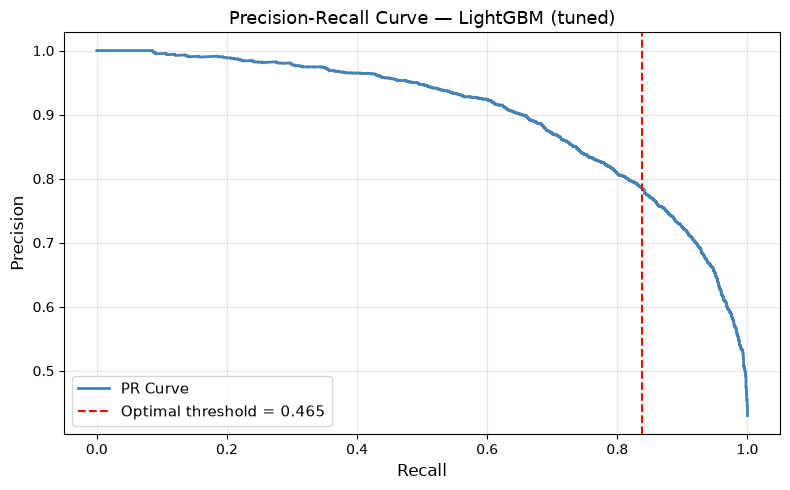

Saved: outputs/precision_recall_curve.png


In [7]:
# Use the best model based on AUC-PR
best_model_name = results_df['AUC-PR'].idxmax()
best_model = dict(candidates)[best_model_name]
print(f'Tuning threshold for: {best_model_name}')

y_prob_best = best_model.predict_proba(X_test)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_best)

f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-9)
best_idx = f1_scores[:-1].argmax()
OPTIMAL_THRESHOLD = float(thresholds[best_idx])

print(f'\nDefault threshold (0.50):')
y_pred_default = (y_prob_best >= 0.50).astype(int)
print(classification_report(y_test, y_pred_default, target_names=['No Failure', 'Failure']))

print(f'Optimal threshold ({OPTIMAL_THRESHOLD:.4f}):')
y_pred_opt = (y_prob_best >= OPTIMAL_THRESHOLD).astype(int)
print(classification_report(y_test, y_pred_opt, target_names=['No Failure', 'Failure']))

# Plot PR curve
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(recalls, precisions, color='steelblue', linewidth=2, label='PR Curve')
ax.axvline(recalls[best_idx], color='red', linestyle='--',
           label=f'Optimal threshold = {OPTIMAL_THRESHOLD:.3f}')
ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title(f'Precision-Recall Curve — {best_model_name}', fontsize=13)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../outputs/precision_recall_curve.png', dpi=150)
plt.show()
print(f'Saved: outputs/precision_recall_curve.png')

## Step 7 — Select and Save Best Model

In [8]:
# Save tuned versions
with open('../models/xgboost_model.pkl', 'wb') as f:
    pickle.dump(best_xgb, f)
with open('../models/lightgbm_model.pkl', 'wb') as f:
    pickle.dump(best_lgbm, f)

# Save best model
best_final_model = best_model
with open('../models/best_model.pkl', 'wb') as f:
    pickle.dump(best_final_model, f)

# Save optimal threshold
with open('../models/optimal_threshold.pkl', 'wb') as f:
    pickle.dump(OPTIMAL_THRESHOLD, f)

print(f'Best model: {best_model_name}')
print(f'Optimal threshold: {OPTIMAL_THRESHOLD:.4f}')
print(f'Saved: models/best_model.pkl')
print(f'Saved: models/optimal_threshold.pkl')

Best model: LightGBM (tuned)
Optimal threshold: 0.4652
Saved: models/best_model.pkl
Saved: models/optimal_threshold.pkl
